# Session 7 — Fine-tuning in practice

Session 6 changed a model's general behaviour with preference data. Most fine-tuning in practice is narrower: you have one task and a few thousand examples, and you want a small model to do that task reliably. This session teaches Qwen2.5-0.5B-Instruct to turn robot log lines into JSON. We compare a prompt with one worked example, LoRA at four ranks, and ordinary fine-tuning of the last four blocks, on log layouts the model was trained on and on two it never saw.

**By the end of the session you should be able to:**

1. set up a fine-tuning task with a test that measures generalisation, and measure a prompting baseline before training anything;
2. implement LoRA from its definition, check that it starts as the original model and merges back into it, and count what it trains;
3. compare LoRA ranks and full fine-tuning on accuracy, forgetting and storage, and find where each one fails.

**To run it yourself** you need the packages from Session 6. The notebook uses Qwen2.5-0.5B-Instruct (about 1 GB, downloaded in Session 6) and the UltraFeedback test split (2 MB). It took 913 s on our laptop GPU, with 109 s for one LoRA training run. It is not practical on a CPU; the saved outputs are the reference.

In [1]:
import re, json, math, time, copy, numpy as np, pandas as pd, matplotlib.pyplot as plt
from aij_common import DEVICE, set_seed
import torch, torch.nn as nn, torch.nn.functional as F
from huggingface_hub import hf_hub_download
from transformers import AutoTokenizer, AutoModelForCausalLM
from transformers.utils import logging
from huggingface_hub.utils import logging as hub_logging
logging.set_verbosity_error(); hub_logging.set_verbosity_error(); set_seed(0)
tok = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-0.5B-Instruct", padding_side="left")
inst = AutoModelForCausalLM.from_pretrained("Qwen/Qwen2.5-0.5B-Instruct", dtype=torch.bfloat16).to(DEVICE).eval()
for p in inst.parameters(): p.requires_grad = False
print(f"Qwen2.5-0.5B-Instruct: {sum(p.numel() for p in inst.parameters()) / 1e6:.0f}M parameters, {len(inst.model.layers)} blocks, hidden size {inst.config.hidden_size}, {inst.config.num_attention_heads} query heads and {inst.config.num_key_value_heads} key/value heads")

Qwen2.5-0.5B-Instruct: 494M parameters, 24 blocks, hidden size 896, 14 query heads and 2 key/value heads


The next cell defines the helpers: the chat template, batched greedy generation, and the training loss. As in Session 6, the loss is computed on the answer tokens only, and the 151,936-way output layer is applied only at those positions, which keeps memory low. Presenters skip it on screen.

In [2]:
def chat_text(prompt, response=None):
    msgs = [{"role": "user", "content": prompt}] + ([{"role": "assistant", "content": response}] if response else [])
    return tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=response is None)

@torch.no_grad()
def generate(model, prompts_, max_new=70, batch=64):
    out = []
    for i in range(0, len(prompts_), batch):
        enc = tok([chat_text(p) for p in prompts_[i:i + batch]], return_tensors="pt", padding=True).to(DEVICE)
        with torch.autocast("cuda", dtype=torch.bfloat16): ids = model.generate(**enc, max_new_tokens=max_new, do_sample=False, pad_token_id=tok.pad_token_id)[:, enc.input_ids.shape[1]:]
        out += tok.batch_decode(ids, skip_special_tokens=True)
    return out

def batch_loss(model, prompts_, responses):
    """Mean next-token loss on the answer tokens only; the prompt is context, not target."""
    enc_p = [tok(chat_text(p)).input_ids for p in prompts_]; enc_r = [tok(r + "<|im_end|>").input_ids for r in responses]
    L = max(len(a) + len(b) for a, b in zip(enc_p, enc_r)); ids = torch.full((len(enc_p), L), tok.pad_token_id); attn = torch.zeros(len(enc_p), L, dtype=torch.long); target = torch.full((len(enc_p), L), -100)
    for i, (a, b) in enumerate(zip(enc_p, enc_r)): ids[i, :len(a) + len(b)] = torch.tensor(a + b); attn[i, :len(a) + len(b)] = 1; target[i, len(a):len(a) + len(b)] = torch.tensor(b)
    ids, attn, target = ids.to(DEVICE), attn.to(DEVICE), target.to(DEVICE)
    with torch.autocast("cuda", dtype=torch.bfloat16):
        h = model.model(input_ids=ids, attention_mask=attn).last_hidden_state[:, :-1]; keep = target[:, 1:] != -100
        logits = model.lm_head(h[keep])                                               # the 151,936-way output only where there is a target
    return F.cross_entropy(logits.float(), target[:, 1:][keep])

## 1. The task and two baselines

Each example is one log line and a JSON answer with five fields. The lines come in six layouts. Training uses 2,000 lines in layouts 0–3. The test has 200 lines in those layouts and 200 in layouts 4 and 5, which never appear in training. The values are random, so the model cannot memorise answers, only learn how to read each layout.

In [3]:
rng = np.random.default_rng(0)
TEMPLATES = ["{time} robot {robot} battery {battery}% charger {charger} status {status}", "[{time}] {robot}: batt={battery}% chg={charger} state={status}",
             "Robot {robot} reported at {time} that its battery is at {battery} percent, docked at charger {charger}, status: {status}.", "{status} | {robot} | {battery}% | {charger} | {time}",
             "At {time}, unit {robot} (charger {charger}) shows {battery}% charge - {status}.", "{robot}/{charger} @ {time} -> level {battery}, flag {status}"]
SEEN, UNSEEN = [0, 1, 2, 3], [4, 5]                                                # the last two layouts are never used for training
def make_example(t):
    f = {"robot": f"R-{rng.integers(1, 40)}", "battery": int(rng.integers(1, 100)), "charger": f"C{rng.integers(1, 10)}", "status": str(rng.choice(["LOW", "OK", "CRITICAL", "CHARGING"])), "time": f"{rng.integers(0, 24):02d}:{rng.integers(0, 60):02d}"}
    return TEMPLATES[t].format(**f), {k: f[k] for k in ("robot", "battery", "charger", "status", "time")}
ask = lambda line: f"Extract the fields from this robot log line as JSON with the keys robot, battery, charger, status and time. Reply with the JSON only.\n\n{line}"
train = [make_example(t) for t in rng.choice(SEEN, 2000)]; test_seen = [make_example(t) for t in rng.choice(SEEN, 200)]; layout_unseen = rng.choice(UNSEEN, 200); test_unseen = [make_example(t) for t in layout_unseen]
for t in range(6): print(f"layout {t}{' (never trained on)' if t in UNSEEN else ''}: {make_example(t)[0]}")
print("\ntarget answer:", json.dumps(train[0][1]))

layout 0: 20:52 robot R-10 battery 36% charger C1 status LOW
layout 1: [06:59] R-33: batt=40% chg=C1 state=LOW
layout 2: Robot R-36 reported at 18:52 that its battery is at 12 percent, docked at charger C4, status: CHARGING.
layout 3: CHARGING | R-29 | 36% | C3 | 23:56
layout 4 (never trained on): At 05:33, unit R-5 (charger C1) shows 16% charge - CRITICAL.
layout 5 (never trained on): R-33/C4 @ 22:13 -> level 66, flag CRITICAL

target answer: {"robot": "R-29", "battery": 2, "charger": "C5", "status": "CHARGING", "time": "18:29"}


Before training anything, we ask the instruct model as it is, in two ways: with the instruction alone (zero-shot), and with one worked example from layout 0 placed in front of the question. An answer counts as right only if all five fields match exactly; the table also gives the share of answers with each field right.

> **Pause:** with one worked example in the prompt, how many of the 200 test lines in the training layouts will the model get fully right?

In [4]:
def parse(o):
    try: return json.loads(re.search(r"\{.*\}", o, re.S).group(0))
    except Exception: return None
def accuracy(model, examples, prompt=None, fields=False):
    """Share of answers with every field right; with fields=True also the share of each field right."""
    outs = generate(model, [(prompt or ask)(line) for line, _ in examples], 70); got = [parse(o) for o in outs]
    ok = float(np.mean([g == truth for g, (_, truth) in zip(got, examples)]))
    if not fields: return ok, outs
    per = {k: float(np.mean([isinstance(g, dict) and g.get(k) == truth[k] for g, (_, truth) in zip(got, examples)])) for k in examples[0][1]}
    return ok, outs, per
shot_line, shot_json = make_example(0)                                                # one worked example, in a layout from the training set
ask_one_shot = lambda line: f"{ask(shot_line)}\n\nAnswer: {json.dumps(shot_json)}\n\nNow this one.\n\n{ask(line)}"
rows = {}
for label, prompt in (("zero-shot", None), ("one example in the prompt", ask_one_shot)):
    for split, data_ in (("seen layouts", test_seen), ("unseen layouts", test_unseen)):
        a, o, per = accuracy(inst, data_, prompt, fields=True); rows[(label, split)] = {"all fields right": a, **per}
        if label == "zero-shot" and split == "seen layouts": outs = o
display(pd.DataFrame(rows).T.round(3))
acc_seen, acc_unseen = rows[("zero-shot", "seen layouts")]["all fields right"], rows[("zero-shot", "unseen layouts")]["all fields right"]
print("zero-shot example:", repr(outs[0][:200]), "\ntruth:", json.dumps(test_seen[0][1]))

all fields right  robot  battery  \
zero-shot                 seen layouts               0.000  0.795      0.0   
                          unseen layouts             0.000  0.420      0.0   
one example in the prompt seen layouts               0.925  0.945      1.0   
                          unseen layouts             0.210  0.235      1.0   

                                          charger  status   time  
zero-shot                 seen layouts      0.405   0.175  0.405  
                          unseen layouts    0.005   0.280  0.720  
one example in the prompt seen layouts      1.000   0.960  0.945  
                          unseen layouts    0.580   1.000  0.770

zero-shot example: '```json\n{\n  "robot": "R-1",\n  "battery": {\n    "value": "98%"\n  },\n  "charger": {\n    "status": "C1",\n    "value": "LOW"\n  }\n}\n```' 
truth: {"robot": "R-1", "battery": 98, "charger": "C1", "status": "LOW", "time": "18:20"}


Zero-shot, no line is fully right, though the model often finds the robot (0.795 on the training layouts). It uses its own structure instead of ours: in the example above `battery` is an object holding the string "98%", the status sits under `charger`, and `time` is missing. Battery is never right zero-shot.

One worked example fixes the format: 0.925 of the lines in the training layouts are fully right. On the two unseen layouts it manages 0.210, and the table shows where it goes wrong: the robot (0.235) and the charger (0.580). Fine-tuning has to beat 0.925 and 0.210 to be worth the trouble.

## 2. LoRA from its definition

Full fine-tuning updates every weight, and every task then needs its own copy of the model. LoRA (Hu et al., 2021) freezes the weights and learns a low-rank change to some of the matrices: a frozen matrix $W$ becomes $W + \frac{\alpha}{r}BA$, where $A$ has $r$ rows and $B$ has $r$ columns, so the change $BA$ has rank at most $r$. $B$ starts at zero, so the adapted model starts out identical to the original. We keep $\alpha = 16$ at every rank, as the paper does, so changing $r$ needs no new learning rate.

The class below wraps one linear layer this way, and `add_lora` wraps the four attention matrices (query, key, value, output) of every block.

In [5]:
class LoRALinear(nn.Module):
    """y = W x + (alpha / r) * B A x, with W frozen and only the small matrices A (r x in) and B (out x r) trained."""
    def __init__(self, base, r, alpha):
        super().__init__(); self.base, self.r, self.scale = base, r, alpha / r
        self.A = nn.Parameter(torch.empty(r, base.in_features, device=base.weight.device)); nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))
        self.B = nn.Parameter(torch.zeros(base.out_features, r, device=base.weight.device))      # B starts at zero, so the model starts out unchanged
    def forward(self, x): return self.base(x) + (x @ self.A.T.to(x.dtype) @ self.B.T.to(x.dtype)) * self.scale
    @torch.no_grad()
    def merged_weight(self): return self.base.weight.float() + self.scale * (self.B @ self.A)

def add_lora(model, r, alpha=16, targets=("q_proj", "k_proj", "v_proj", "o_proj")):        # alpha stays fixed while r varies, as in the LoRA paper, so the scale alpha / r shrinks as r grows
    model = copy.deepcopy(model)
    for layer in model.model.layers:
        for name in targets:
            holder = layer.self_attn if name in ("q_proj", "k_proj", "v_proj", "o_proj") else layer.mlp
            setattr(holder, name, LoRALinear(getattr(holder, name), r, alpha))
    return model

def lora_parameters(model): return [p for n, p in model.named_parameters() if n.endswith(".A") or n.endswith(".B")]
m = add_lora(inst, 8); x = tok(["The battery is empty."], return_tensors="pt").to(DEVICE)
with torch.no_grad(): same = (m(**x).logits - inst(**x).logits).abs().max().item()
n_lora = sum(p.numel() for p in lora_parameters(m)); n_all = sum(p.numel() for p in inst.parameters())
print(f"largest difference in the logits between the model with fresh adapters and the original: {same}")
print(f"rank 8 adapters on the four attention matrices of all 24 blocks: {n_lora:,} trainable parameters = {100 * n_lora / n_all:.2f}% of the model's {n_all / 1e6:.0f}M")
q = inst.model.layers[0].self_attn.q_proj; print(f"one query matrix: {tuple(q.weight.shape)} = {q.weight.numel():,} weights; its rank-8 update has {8 * (q.in_features + q.out_features):,} trainable numbers")

largest difference in the logits between the model with fresh adapters and the original: 0.0
rank 8 adapters on the four attention matrices of all 24 blocks: 1,081,344 trainable parameters = 0.22% of the model's 494M
one query matrix: (896, 896) = 802,816 weights; its rank-8 update has 14,336 trainable numbers


With fresh adapters the logits are identical to the original model's (largest difference 0.0), because $B=0$. Rank 8 on four matrices in each of the 24 blocks trains 1,081,344 numbers, 0.22% of the model. One query matrix has 802,816 weights, and its rank-8 change has 14,336. The key and value matrices are smaller, 896×128, because Qwen shares each key and value head between several query heads (Session 9 measures what that saves).

## 3. Training

We train for 250 steps of 16 examples (two passes over the 2,000 lines) at learning rate $2\times10^{-4}$, with a short warm-up and cosine decay. To measure forgetting, we track the loss on 64 general assistant answers from UltraFeedback's test split, which have nothing to do with robots.

In [6]:
def finetune(model, params, steps, lr, batch=16, seed=0, log_every=10):
    g = torch.Generator().manual_seed(seed); opt = torch.optim.AdamW(params, lr=lr, weight_decay=0.0); log = []; model.train()
    for step in range(steps):
        idx = torch.randint(0, len(train), (batch,), generator=g).tolist(); lr_now = lr * min(1, (step + 1) / 20) * (0.5 * (1 + math.cos(math.pi * step / steps)) * 0.9 + 0.1)
        for gr in opt.param_groups: gr["lr"] = lr_now
        loss = batch_loss(model, [ask(train[i][0]) for i in idx], [json.dumps(train[i][1]) for i in idx]); opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(params, 1.0); opt.step()
        if step % log_every == 0: log.append({"step": step, "loss": loss.item()})
    model.eval(); return pd.DataFrame(log)
uf_test = pd.read_parquet(hf_hub_download("trl-lib/ultrafeedback_binarized", "data/test-00000-of-00001.parquet", repo_type="dataset"))
general = [(p, c) for p, c in ((r.chosen[0]["content"], r.chosen[-1]["content"]) for r in uf_test.itertuples()) if len(c) < 900][:64]      # 64 short assistant answers, to measure forgetting
@torch.no_grad()
def general_loss(model): return float(np.mean([batch_loss(model, [p for p, _ in general[i:i + 16]], [c for _, c in general[i:i + 16]]).item() for i in range(0, 64, 16)]))
base_general = general_loss(inst); print(f"loss on 64 general assistant answers before any training: {base_general:.3f}")

loss on 64 general assistant answers before any training: 1.290


Before training, that loss is 1.290 nats per token.

In [7]:
set_seed(0); lora8 = add_lora(inst, 8); t = time.time(); log8 = finetune(lora8, lora_parameters(lora8), steps=250, lr=2e-4)
print(f"250 steps in {time.time() - t:.0f} s; loss {log8.loss.iloc[0]:.3f} at the start, {log8.loss.iloc[-5:].mean():.3f} at the end")
(a_s, outs_s), (a_u, outs_u) = accuracy(lora8, test_seen), accuracy(lora8, test_unseen)
print(f"after LoRA (rank 8): accuracy on the training layouts {a_s:.3f}, on layouts never seen {a_u:.3f}; loss on general answers {general_loss(lora8):.3f} (was {base_general:.3f})")
got = [parse(o) for o in outs_u]
for t in UNSEEN:
    idx = [i for i in range(200) if layout_unseen[i] == t]
    per = {k: np.mean([isinstance(got[i], dict) and got[i].get(k) == test_unseen[i][1][k] for i in idx]) for k in test_unseen[0][1]}
    print(f"layout {t} ({len(idx)} lines), share right per field:", {k: round(float(v), 2) for k, v in per.items()}, f"| all fields: {np.mean([got[i] == test_unseen[i][1] for i in idx]):.2f}")
for t in UNSEEN:
    i = next((i for i in range(200) if layout_unseen[i] == t and got[i] != test_unseen[i][1]), None)
    if i is not None: print(f"layout {t}: {test_unseen[i][0]}\n  answer: {outs_u[i]}\n  truth:  {json.dumps(test_unseen[i][1])}")

250 steps in 109 s; loss 0.315 at the start, 0.000 at the end


after LoRA (rank 8): accuracy on the training layouts 1.000, on layouts never seen 0.520; loss on general answers 1.355 (was 1.290)
layout 4 (103 lines), share right per field: {'robot': 1.0, 'battery': 1.0, 'charger': 1.0, 'status': 1.0, 'time': 1.0} | all fields: 1.00
layout 5 (97 lines), share right per field: {'robot': 0.01, 'battery': 1.0, 'charger': 0.96, 'status': 0.99, 'time': 1.0} | all fields: 0.01
layout 5: R-25/C3 @ 18:21 -> level 23, flag OK
  answer: {"robot": "R-25/C3", "battery": 23, "charger": "C3", "status": "OK", "time": "18:21"}
  truth:  {"robot": "R-25", "battery": 23, "charger": "C3", "status": "OK", "time": "18:21"}


Training took 109 s. The loss on the training answers falls from 0.315 to 0.000: the model has learned this format completely. Every test line in the training layouts is right (1.000), and on the unseen layouts 0.520, against 0.210 with one example in the prompt. The loss on general answers rose from 1.290 to 1.355, a small amount of forgetting.

The 0.520 averages two very different results. Layout 4, a sentence with wording the model never saw, is solved completely (1.00). Layout 5 is almost never right (0.01), and one field is to blame: the model copies `R-25/C3` whole into `robot`. No training line joins two fields with a slash, so nothing in training showed the model where the robot name ends.

## 4. Rank, and full fine-tuning

Now the same training at ranks 1, 4 and 32, and for comparison ordinary fine-tuning of every weight in the last four blocks (60M parameters, learning rate $2\times10^{-5}$, everything else the same). Each model is scored on the training layouts, on each unseen layout separately, and on the general answers.

> **Pause:** rank 32 trains 32 times as many numbers as rank 1. Which of them, if either, will read layout 5?

In [8]:
def score(model, prompt=None):
    """Accuracy on the training layouts, and separately on each of the two unseen layouts."""
    out = {"seen layouts": accuracy(model, test_seen, prompt)[0]}; got = [parse(o) for o in accuracy(model, test_unseen, prompt)[1]]
    for t in UNSEEN: out[f"layout {t} (unseen)"] = float(np.mean([got[i] == test_unseen[i][1] for i in range(200) if layout_unseen[i] == t]))
    return out
results = {"no training": {"parameters": 0, **score(inst), "general loss": base_general}, "one example in the prompt": {"parameters": 0, **score(inst, ask_one_shot), "general loss": base_general}}
results["LoRA rank 8"] = {"parameters": sum(p.numel() for p in lora_parameters(lora8)), **score(lora8), "general loss": general_loss(lora8)}
adapters = {"LoRA rank 8": lora8}
for r in (1, 4, 32):
    set_seed(0); m = add_lora(inst, r); finetune(m, lora_parameters(m), steps=250, lr=2e-4)
    results[f"LoRA rank {r}"] = {"parameters": sum(p.numel() for p in lora_parameters(m)), **score(m), "general loss": general_loss(m)}
    del m; torch.cuda.empty_cache()                                               # each wrapped copy holds a full 1 GB model; keep only rank 8 for later

In [9]:
full = copy.deepcopy(inst).float()
for p in full.parameters(): p.requires_grad = False
last = [p for blk in full.model.layers[-4:] for p in blk.parameters()]
for p in last: p.requires_grad = True
set_seed(0); finetune(full, last, steps=250, lr=2e-5)
results["last 4 blocks, all weights"] = {"parameters": sum(p.numel() for p in last), **score(full), "general loss": general_loss(full)}
table = pd.DataFrame(results).T; table["parameters"] = table["parameters"].astype(int); display(table.round(3))
print(f"{sum(layout_unseen == 4)} test lines in layout 4 and {sum(layout_unseen == 5)} in layout 5; one line is worth about 1 point")

,parameters,seen layouts,layout 4 (unseen),layout 5 (unseen),general loss
no training,0,0.000,0.000,0.000,1.290
one example in the prompt,0,0.925,0.359,0.052,1.290
LoRA rank 8,1081344,1.000,1.000,0.010,1.355
LoRA rank 1,135168,1.000,1.000,0.052,1.364
LoRA rank 4,540672,1.000,1.000,0.000,1.355
LoRA rank 32,4325376,1.000,1.000,0.010,1.349
"last 4 blocks, all weights",59649536,1.000,0.951,0.268,1.315


103 test lines in layout 4 and 97 in layout 5; one line is worth about 1 point


Rank makes no visible difference. Ranks 1 to 32 all get every line in the training layouts and in layout 4 right, and all fail on layout 5 (0.000 to 0.052, that is 0 to 5 of 97 lines). Their losses on general answers lie between 1.349 and 1.364. Rank 1 trains 135,168 numbers, 0.03% of the model, and does as well as rank 32. The LoRA paper reports the same pattern on its tasks: very small ranks were enough.

Fine-tuning all weights of the last four blocks is the only setting that reads some of layout 5 (0.268). It loses a little on layout 4 (0.951) and forgets less (1.315, against about 1.35 for LoRA), while training about 440 times as many numbers as rank 1. Each of these numbers comes from one training run, a test line is worth about one point, and the two methods differ in more than the method (LoRA changes the attention of all 24 blocks, with a learning rate ten times higher), so read the comparison as rough. Session 11 measures how much results like these move between runs.

What the table shows clearly is the limit set by the data. No setting learned layout 5 well, because nothing like it was in the training set, and a bigger adapter did not help.

## 5. What the update looks like

Two practical properties matter for deployment: an adapter can be merged into the weights, so the fine-tuned model runs at the original speed, and it is small to store. We also look at a question the LoRA paper raised: is the change that fine-tuning makes low-rank to begin with?

merged weights vs adapter, same random input, both in fp32: largest difference 9.5e-07 (outputs are of size about 0.92)
storing the merged matrix in bf16 changes its outputs by up to 5.9e-03
rank of the rank-8 update: 8; singular values of the full fine-tuning update of the last block's query matrix: first 8 hold 84% of its energy, first 32 hold 95%


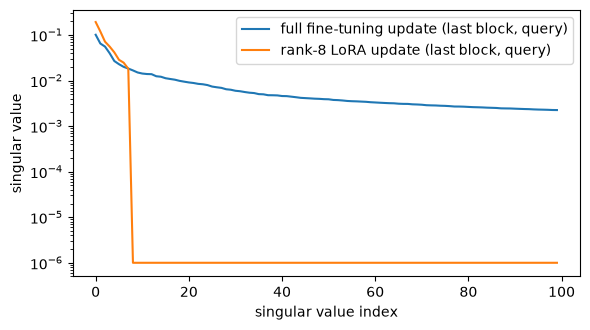

In [10]:
q_lora = adapters["LoRA rank 8"].model.layers[-1].self_attn.q_proj                # the same matrix the full fine-tuning changed
with torch.no_grad():
    delta_lora = (q_lora.scale * (q_lora.B @ q_lora.A)).float(); delta_full = (full.model.layers[-1].self_attn.q_proj.weight.float() - inst.model.layers[-1].self_attn.q_proj.weight.float())
    s_full = torch.linalg.svdvals(delta_full.cpu()); s_lora = torch.linalg.svdvals(delta_lora.cpu())
    x = torch.randn(4, 896, device=DEVICE); W0, b = q_lora.base.weight.float(), q_lora.base.bias.float()
    adapter_out = x @ W0.T + b + q_lora.scale * (x @ q_lora.A.T @ q_lora.B.T); merged_out = x @ q_lora.merged_weight().T + b      # both in fp32
print(f"merged weights vs adapter, same random input, both in fp32: largest difference {(adapter_out - merged_out).abs().max().item():.1e} (outputs are of size about {merged_out.abs().mean().item():.2f})")
print(f"storing the merged matrix in bf16 changes its outputs by up to {(x @ q_lora.merged_weight().to(torch.bfloat16).float().T + b - merged_out).abs().max().item():.1e}")
print(f"rank of the rank-8 update: {int((s_lora > 1e-6 * s_lora[0]).sum())}; singular values of the full fine-tuning update of the last block's query matrix: first 8 hold {100 * (s_full[:8] ** 2).sum() / (s_full ** 2).sum():.0f}% of its energy, first 32 hold {100 * (s_full[:32] ** 2).sum() / (s_full ** 2).sum():.0f}%")
plt.figure(figsize=(6, 3.4)); plt.semilogy(s_full[:100], label="full fine-tuning update (last block, query)"); plt.semilogy(s_lora[:100].clamp(min=1e-6), label="rank-8 LoRA update (last block, query)"); plt.ylim(5e-7, None); plt.xlabel("singular value index"); plt.ylabel("singular value"); plt.legend(); plt.tight_layout(); plt.show()

Merging is exact: computing $Wx + \frac{\alpha}{r}BAx$ and $(W + \frac{\alpha}{r}BA)x$ in fp32 gives outputs that differ by at most $9.5\times10^{-7}$, on outputs of size about 0.92. Storing the merged matrix in bf16, the model's usual format, moves the outputs by up to 0.006, the ordinary rounding of bf16.

The plot compares the singular values of two changes to the same matrix, the last block's query. The rank-8 LoRA update has exactly 8 non-zero singular values; the rest are zero, drawn at the plot's floor. The change made by full fine-tuning was free to use any rank, and it has many non-zero singular values, but they fall off quickly: the first 8 hold 84% of its energy (the sum of squared singular values) and the first 32 hold 95%. Even unconstrained, most of the change lies in a few directions, which is why a low rank loses little.

In [11]:
import os, tempfile
state = {n: p.detach().cpu() for n, p in adapters["LoRA rank 8"].named_parameters() if n.endswith(".A") or n.endswith(".B")}
path = os.path.join(tempfile.gettempdir(), "adapter_r8.pt"); torch.save(state, path); print(f"the rank-8 adapter file: {os.path.getsize(path) / 1e6:.1f} MB; the base model in bf16: {n_all * 2 / 1e6:.0f} MB")

the rank-8 adapter file: 4.4 MB; the base model in bf16: 988 MB


The rank-8 adapter for all 24 blocks takes 4.4 MB, against 988 MB for the model in bf16. One copy of the base model can serve many tasks, each with its own small file.

## What to take away

- Measure a prompt with a worked example before fine-tuning. Here one example already reached 0.925 on the familiar layouts.
- Test on inputs unlike the training data, and break the score down. An average of 0.52 hid one new layout solved and one failed.
- LoRA trains a fraction of a percent of the weights, starts exactly at the original model and merges back exactly. On this task the rank hardly mattered.
- Fine-tuning learns what the data shows. When a case fails, look at the training data before reaching for a bigger adapter.
- Track forgetting with a loss on unrelated text: here it rose from 1.290 to about 1.35 with LoRA.

---

# Going deeper

Reading for after the session.

## The LoRA paper

Hu et al. (2021), *LoRA: Low-Rank Adaptation of Large Language Models*, adapted only attention matrices and found ranks as low as 1 or 2 competitive on their tasks with GPT-3. The paper's text says $A$ is initialised from a Gaussian; the authors' released code uses a uniform (Kaiming) initialisation, as we do. Session 12 reads the paper closely and tests some of its claims at small scale.

## Why $\alpha/r$

With Adam, the size of each update is roughly set by the learning rate, whatever the gradient's scale. Scaling the adapter's output by $\alpha/r$ keeps the size of the change $\frac{\alpha}{r}BA$ roughly independent of $r$, so a learning rate tuned at one rank carries over to another. The paper sets $\alpha$ to the first rank it tries and leaves it there.

## Which matrices

We adapted the four attention matrices. Many recipes also adapt the MLP matrices, which hold most of a block's weights. For a fixed number of trainable parameters, the paper found it better to spread a low rank over several matrices than to put a high rank on one.

## QLoRA

Dettmers et al. (2023), *QLoRA: Efficient Finetuning of Quantized LLMs*, kept the frozen base model in 4-bit precision and trained 16-bit adapters on top, which made fine-tuning much larger models possible on a single GPU. Session 9 shows what 4-bit rounding does to a model's weights.

## LoRA and forgetting

Biderman et al. (2024), *LoRA Learns Less and Forgets Less*, compared LoRA with full fine-tuning on code and mathematics and found that LoRA learned the target task less well and kept more of the model's other abilities. Our single run on a toy task, against fine-tuning of only the last four blocks, came out the other way on forgetting; with that difference in setup it says little either way.